# Wycena laptopów — zadanie na 30 minut
**Random Forest i Gradient Boosting · ćwiczenie dla kursantów**

**Cel:** sprawdzić, czy zmiana parametrów poprawia przewidywanie ceny laptopa. Porównasz dwa gotowe modele regresji, wykonasz po jednej zmianie dla każdego i wybierzesz najlepszą konfigurację.

Dane to **1200 syntetycznych ofert**, a nie aktualne ceny rynkowe. Przewidujemy cenę ofertową w PLN. Notebook jest samodzielny — nie wymaga pliku CSV.

| Czas | Co robisz? |
|---|---|
| 0–5 min | Uruchamiasz przygotowanie danych i narzędzia |
| 5–10 min | Porównujesz dwa modele bazowe |
| 10–15 min | Zmieniasz jeden parametr Random Forest |
| 15–20 min | Zmieniasz jeden parametr Gradient Boosting |
| 20–25 min | Porównujesz cztery konfiguracje i wykonujesz test |
| 25–30 min | Wyceniasz laptop i zapisujesz trzy wnioski |

**Oddajesz:** ten notebook z tabelą czterech konfiguracji i trzema krótkimi odpowiedziami. Bez dodatkowego raportu, eksportu czy kolejnych eksperymentów.

**Dla prowadzącego:** środowisko powinno mieć wcześniej zainstalowane numpy, pandas, matplotlib i scikit-learn. Limit 30 minut zakłada gotowe środowisko. Kod przygotowujący dane jest gotowy; kursanci nie przepisują go ani nie analizują generatora linia po linii.

Uruchamiaj komórki od góry przez Shift+Enter. Edytujesz tylko dwie wartości parametrów i odpowiedzi. Nie zmieniaj danych ani podziału. Test otwórz dopiero po porównaniu czterech konfiguracji.

## 1. Uruchom przygotowanie — 5 minut
Model korzysta z marki, wydajności CPU, RAM, SSD, klasy GPU, wieku, stanu, gwarancji i kondycji baterii.

**Trening 60%** służy uczeniu; **walidacja 20%** służy wyborowi konfiguracji; **test 20%** służy końcowej ocenie. ID oferty nie jest cechą. Braki liczb uzupełniamy medianą treningu, a marki i inne kategorie kodujemy one-hot. Drzewa nie wymagają skalowania.

In [1]:
# %pip install numpy pandas matplotlib scikit-learn
import sys, time, json, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True})
SEED = 42
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)

Python: 3.12.14 | scikit-learn: 1.8.0


In [2]:
def generuj_oferty(n=1200, seed=SEED):
    rng = np.random.default_rng(seed)
    d = pd.DataFrame({
        'id_oferty': np.arange(1, n+1),
        'marka': rng.choice(['Alfa', 'Beta', 'Gamma', 'Delta'], n),
        'cpu_punkty': rng.integers(1500, 16001, n),
        'ram_gb': rng.choice([8, 16, 32, 64], n, p=[0.25, 0.40, 0.28, 0.07]),
        'ssd_gb': rng.choice([256, 512, 1024, 2048], n, p=[0.20, 0.40, 0.32, 0.08]),
        'gpu_klasa': rng.choice(['brak', 'podstawowa', 'srednia', 'wysoka'], n, p=[0.4, 0.25, 0.25, 0.1]),
        'wiek_mies': rng.integers(3, 85, n),
        'stan': rng.choice(['dostateczny', 'dobry', 'bardzo_dobry'], n, p=[0.15, 0.5, 0.35]),
        'gwarancja_mies': rng.choice([0, 6, 12], n, p=[0.65, 0.2, 0.15])
    })
    d['bateria_proc'] = np.clip(100 - 0.5*d.wiek_mies + rng.normal(0, 8, n), 35, 100).round()
    baza = (900 + 0.22*d.cpu_punkty + 22*d.ram_gb + 0.22*d.ssd_gb
        + d.gpu_klasa.map({'brak': 0, 'podstawowa': 450, 'srednia': 1200, 'wysoka': 2300})
        + d.marka.map({'Alfa': 0, 'Beta': 180, 'Gamma': 350, 'Delta': 550}))
    cena = (baza * np.exp(-d.wiek_mies/110)
        * d.stan.map({'dostateczny': 0.76, 'dobry': 0.9, 'bardzo_dobry': 1.0})
        + 12*d.gwarancja_mies - 8*np.maximum(75-d.bateria_proc, 0)
        + 350*((d.gpu_klasa == 'wysoka') & (d.ram_gb >= 32)))
    # Szum zależy od ceny: droższe oferty mają większy rozrzut w PLN.
    d['cena_pln'] = np.maximum(250, cena + rng.normal(0, 100 + 0.06*cena, n)).round(0)
    for col in ['bateria_proc', 'ssd_gb']:
        d.loc[rng.choice(n, int(0.03*n), replace=False), col] = np.nan
    return d

dane = generuj_oferty()
X = dane.drop(columns=['cena_pln', 'id_oferty'])
y = dane['cena_pln']
# 60% trening, 20% walidacja, 20% test. Testu jeszcze nie analizujemy.
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=SEED)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_dev.index).isdisjoint(X_test.index)
print('Trening / walidacja / test:', len(X_train), len(X_val), len(X_test))

Trening / walidacja / test: 720 240 240


### Gotowe narzędzia — uruchom bez zmian
**MAE** to średni bezwzględny błąd ceny w PLN: niżej = lepiej. MAE=250 PLN nie gwarantuje, że każda wycena ma błąd mniejszy niż 250 PLN.

Porównujemy MAE treningu i walidacji. Bardzo niski błąd treningowy przy wysokim walidacyjnym może wskazywać przeuczenie. Baseline zawsze przewiduje medianę cen treningowych.

In [3]:
def zbuduj_pipeline(X_przyklad, estimator):
    numeric = X_przyklad.select_dtypes(include='number').columns.tolist()
    categorical = X_przyklad.select_dtypes(exclude='number').columns.tolist()
    # Zgodność ze starszymi i nowszymi wydaniami sklearn.
    try:
        encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
    prep = ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), numeric),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('encoder', encoder)]), categorical)
    ])
    return Pipeline([('prep', prep), ('model', clone(estimator))])

In [4]:
wyniki, modele = {}, {}
def ocen(nazwa, estimator):
    model = zbuduj_pipeline(X_train, estimator)
    model.fit(X_train, y_train)
    modele[nazwa] = model
    wyniki[nazwa] = {
        'konfiguracja': nazwa,
        'MAE_trening': mean_absolute_error(y_train, model.predict(X_train)),
        'MAE_walidacja': mean_absolute_error(y_val, model.predict(X_val))}
    return pd.DataFrame([wyniki[nazwa]]).round(1)

def ranking():
    return pd.DataFrame(wyniki.values()).sort_values('MAE_walidacja')

baseline = DummyRegressor(strategy='median').fit(X_train, y_train)
mae_baseline = mean_absolute_error(y_val, baseline.predict(X_val))
print(f'Baseline — MAE walidacji: {mae_baseline:.1f} PLN')
display(X_train.head(3))

Baseline — MAE walidacji: 814.7 PLN


,marka,cpu_punkty,ram_gb,ssd_gb,gpu_klasa,wiek_mies,stan,gwarancja_mies,bateria_proc
1161,Beta,12397,8,512.0,podstawowa,20,dobry,12,78.0
465,Delta,7244,32,256.0,srednia,6,dobry,6,100.0
772,Alfa,11387,32,1024.0,podstawowa,30,dobry,0,83.0


## 2. Porównaj modele bazowe — 5 minut
**Random Forest:** uśrednia prognozy wielu zróżnicowanych drzew.
**Gradient Boosting:** dodaje kolejne drzewa poprawiające dotychczasowy model.

Uruchom kod. Wskaż, który model ma niższy błąd walidacyjny. Sprawdź, czy oba pokonują medianę. Nie wybieraj modelu według błędu treningowego.

In [5]:
RF_BAZA = dict(n_estimators=80, max_depth=8, min_samples_leaf=2, random_state=SEED, n_jobs=-1)
GB_BAZA = dict(n_estimators=80, learning_rate=0.05, max_depth=2, random_state=SEED)
display(ocen('RF_baza', RandomForestRegressor(**RF_BAZA)))
display(ocen('GB_baza', GradientBoostingRegressor(**GB_BAZA)))

,konfiguracja,MAE_trening,MAE_walidacja
0,RF_baza,196.5,373.7


,konfiguracja,MAE_trening,MAE_walidacja
0,GB_baza,353.3,416.8


## 3. Zmień Random Forest — 5 minut
1. Zapisz hipotezę w komentarzu: czy głębsze drzewo poprawi wynik na nowych danych?
2. W kodzie zmień **tylko `GLEBOKOSC_RF` z 8 na 4 albo 16**.
3. Uruchom komórkę i porównaj `RF_zmiana` z `RF_baza`.
4. Sprawdź oba błędy: czy poprawił się tylko trening, czy także walidacja?

`max_depth` ogranicza głębokość drzewa. Wykonaj jedną zmianę; pozostałych ustawień nie ruszaj.

In [6]:
# Moja hipoteza: ...
GLEBOKOSC_RF = 8  # ZADANIE: wpisz 4 albo 16.
rf_zmieniony = RandomForestRegressor(**{**RF_BAZA, 'max_depth': GLEBOKOSC_RF})
display(ocen('RF_zmiana', rf_zmieniony))

,konfiguracja,MAE_trening,MAE_walidacja
0,RF_zmiana,196.5,373.7


## 4. Zmień Gradient Boosting — 5 minut
1. Zapisz hipotezę: co da większa liczba małych poprawek?
2. Zmień **tylko `LICZBA_DRZEW_GB` z 80 na 160**.
3. Uruchom komórkę i porównaj `GB_zmiana` z `GB_baza`.
4. Sprawdź, czy dodatkowe drzewa zmniejszyły błąd walidacyjny.

`n_estimators` określa liczbę kolejnych drzew. Tempo uczenia i głębokość pozostają stałe, aby badać wpływ jednej zmiennej.

In [7]:
# Moja hipoteza: ...
LICZBA_DRZEW_GB = 80  # ZADANIE: wpisz 160.
gb_zmieniony = GradientBoostingRegressor(**{**GB_BAZA, 'n_estimators': LICZBA_DRZEW_GB})
display(ocen('GB_zmiana', gb_zmieniony))

,konfiguracja,MAE_trening,MAE_walidacja
0,GB_zmiana,353.3,416.8


## 5. Porównaj i przetestuj — 5 minut
1. Uruchom ranking czterech konfiguracji. Najniższy MAE walidacyjny wskazuje kandydata.
2. Sprawdź, czy rzeczywiście zmieniłeś parametry — w przeciwnym razie wyniki powtórzą bazę.
3. Po zakończeniu zmian ustaw `KONIEC_EKSPERYMENTOW = True` i uruchom test.
4. Zapisz MAE testowe. Nie wracaj do strojenia po jego obejrzeniu.

Dla prostoty nie uczymy modelu ponownie na treningu+walidacji. Testujemy dokładnie ten model, który wybraliśmy na walidacji. Wynik dotyczy tej symulacji i tego podziału.

Kandydat z walidacji: RF_baza


,konfiguracja,MAE_trening,MAE_walidacja
0,RF_baza,196.5,373.7
2,RF_zmiana,196.5,373.7
1,GB_baza,353.3,416.8
3,GB_zmiana,353.3,416.8


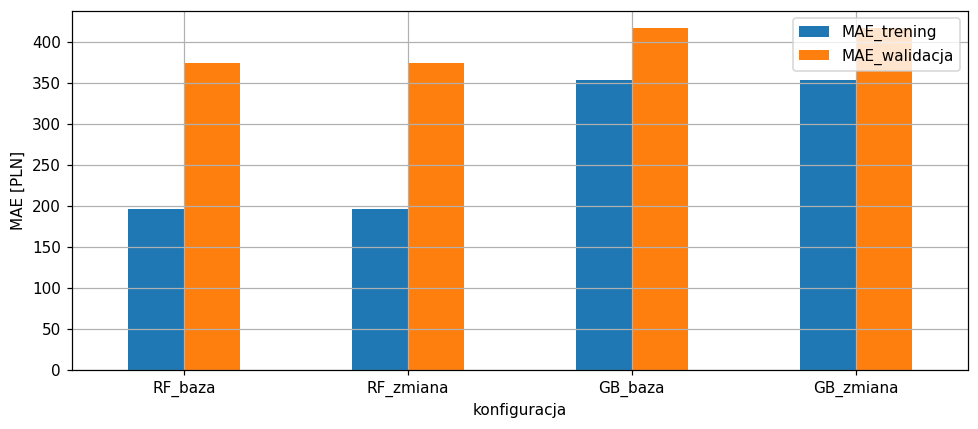

In [8]:
tabela = ranking()
display(tabela.round(1))
tabela.set_index('konfiguracja')[['MAE_trening', 'MAE_walidacja']].plot.bar(rot=0)
plt.ylabel('MAE [PLN]'); plt.tight_layout(); plt.show()
wybrany = tabela.iloc[0]['konfiguracja']
print('Kandydat z walidacji:', wybrany)

In [9]:
KONIEC_EKSPERYMENTOW = False  # ZADANIE: ustaw True dopiero po porównaniu.
if KONIEC_EKSPERYMENTOW:
    if GLEBOKOSC_RF == 8 or LICZBA_DRZEW_GB == 80:
        raise ValueError('Najpierw wykonaj obie zmiany parametrów i ponownie uruchom ranking.')
    model_finalny = modele[wybrany]
    mae_test = mean_absolute_error(y_test, model_finalny.predict(X_test))
    print(f'Wybrany model: {wybrany}; MAE testowe: {mae_test:.1f} PLN')
else:
    print('Test zamknięty — najpierw wykonaj i porównaj obie zmiany.')

Test zamknięty — najpierw wykonaj i porównaj obie zmiany.


## 6. Wyceń laptop i zapisz wnioski — 5 minut
Uruchom gotowy przykład wyceny. Cena pochodzi z modelu syntetycznych danych, nie z bieżącego rynku. Następnie uzupełnij trzy odpowiedzi poniżej — po jednym lub dwóch zdaniach.

In [10]:
laptop = pd.DataFrame([{
    'marka':'Beta', 'cpu_punkty':9000, 'ram_gb':16, 'ssd_gb':512,
    'gpu_klasa':'srednia', 'wiek_mies':24, 'stan':'dobry',
    'gwarancja_mies':6, 'bateria_proc':85
}])
print(f'Przykładowa cena modelowa: {modele[wybrany].predict(laptop)[0]:.0f} PLN')
display(laptop)

Przykładowa cena modelowa: 3060 PLN


,marka,cpu_punkty,ram_gb,ssd_gb,gpu_klasa,wiek_mies,stan,gwarancja_mies,bateria_proc
0,Beta,9000,16,512,srednia,24,dobry,6,85


### Odpowiedzi kursanta — to jest Twoje oddanie zadania
1. **Random Forest:** zmieniłem głębokość z 8 na … . MAE walidacyjne zmieniło się z … na … PLN. Oznacza to, że … .
2. **Gradient Boosting:** zwiększyłem liczbę drzew z 80 do 160. MAE walidacyjne zmieniło się z … na … PLN. Oznacza to, że … .
3. **Wybór:** wybrałem …, ponieważ … . MAE na teście wynosi … PLN. Nie traktuję przykładowej wyceny jako rzeczywistej ceny rynkowej, ponieważ … .

**Gotowe, jeśli:** masz cztery wiersze porównania, wykonałeś dwie zmiany parametrów, jeden końcowy test i uzupełniłeś trzy odpowiedzi. Poprawny eksperyment może zakończyć się pogorszeniem — to także wartościowy wynik.